# 03 - DeepAR Demand Forecasting

**Role in the project:** train one global recurrent neural network across Walmart's California product-store series and produce 28-day forecasts for the shared evaluation pipeline.

This notebook:

1. Loads the prepared daily demand data from `01_data_prep.ipynb`.
2. Reads the team's chronological validation and test windows.
3. Trains the same DeepAR specification on an expanding history for each window.
4. Measures mean absolute error (MAE) without using future observations during training.
5. Saves row-level forecasts in the same schema used by the other models.

> Start with `SAMPLE = True` to confirm the workflow on 100 series. Set it to `False` only for the final full-data run.

## 0 - Settings

These are the only values that normally need editing. `OVERWRITE = False` reuses an existing forecast file; set it to `True` after changing the model specification.

In [1]:
SAMPLE = True
OVERWRITE = False

DRIVE_DIR = "/content/drive/MyDrive/AML_Term_Project"
DATA_DIR = f"{DRIVE_DIR}/data"
OUT_DIR = f"{DATA_DIR}/forecasts_sample" if SAMPLE else f"{DATA_DIR}/forecasts"

WINDOW_NAMES = ("val_1", "val_2", "test")
OUTPUT_FILES = {
    "val_1": "deepar_val1.parquet",
    "val_2": "deepar_val2.parquet",
    "test": "deepar_test.parquet",
}

## 1 - Install and import dependencies

`NeuralForecast` supplies the DeepAR implementation. The remaining packages handle data, reproducibility, timing, and plotting.

In [2]:
%pip install -q neuralforecast

In [3]:
import json
import os
import time

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch

from neuralforecast import NeuralForecast
from neuralforecast.losses.pytorch import DistributionLoss
from neuralforecast.models import DeepAR

SEED = 42
np.random.seed(SEED)
torch.manual_seed(SEED)

print("PyTorch version:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())

PyTorch version: 2.14.1+cpu
CUDA available: False


## 2 - Load the prepared demand data

The data-preparation notebook creates one row per product-store-day using NeuralForecast's required column names:

- `unique_id`: product-store series identifier
- `ds`: date
- `y`: daily unit sales

This DeepAR specification is **univariate**: it learns from sales history only. Price and event variables remain available for models designed to use those covariates.

In [4]:
try:
    from google.colab import drive
    drive.mount("/content/drive")
except ImportError:
    print("Not running in Colab; using the paths from Settings as-is.")

os.makedirs(OUT_DIR, exist_ok=True)

file_name = "ca_sample100.parquet" if SAMPLE else "ca_sales.parquet"
data_path = f"{DATA_DIR}/{file_name}"
df = pd.read_parquet(data_path)

required_columns = {"unique_id", "ds", "y"}
missing_columns = required_columns.difference(df.columns)
if missing_columns:
    raise ValueError(f"Missing required columns: {sorted(missing_columns)}")

df = df.copy()
df["unique_id"] = df["unique_id"].astype(str)
df["ds"] = pd.to_datetime(df["ds"])
df["y"] = pd.to_numeric(df["y"], errors="raise")
df = df.sort_values(["unique_id", "ds"]).reset_index(drop=True)

if df.duplicated(["unique_id", "ds"]).any():
    raise ValueError("Found duplicate unique_id/date rows.")
if df[["unique_id", "ds", "y"]].isna().any().any():
    raise ValueError("The modeling columns contain missing values.")

print(f"Loaded {len(df):,} rows from {data_path}")
print(f"Series: {df['unique_id'].nunique():,}")
print(f"Date range: {df['ds'].min().date()} to {df['ds'].max().date()}")
df[["unique_id", "ds", "y"]].head()

Mounted at /content/drive
Loaded 146,311 rows from /content/drive/MyDrive/AML_Term_Project/data/ca_sample100.parquet
Series: 100
Date range: 2011-01-29 to 2016-05-22


,unique_id,ds,y
0,FOODS_1_040_CA_4,2011-01-29,1.0
1,FOODS_1_040_CA_4,2011-01-30,2.0
2,FOODS_1_040_CA_4,2011-01-31,0.0
3,FOODS_1_040_CA_4,2011-02-01,2.0
4,FOODS_1_040_CA_4,2011-02-02,0.0


## 3 - Read the shared evaluation windows

The test set is the final 28 days. The two preceding 28-day windows are used for validation. For every window, training stops the day before that window begins, so future demand cannot leak into the model.

In [5]:
with open(f"{DATA_DIR}/windows.json", encoding="utf-8") as file:
    windows = json.load(file)

H = int(windows["horizon"])

window_rows = []
for window_name in WINDOW_NAMES:
    start = pd.Timestamp(windows[window_name]["start"])
    end = pd.Timestamp(windows[window_name]["end"])
    days = (end - start).days + 1
    if days != H:
        raise ValueError(f"{window_name} contains {days} days; expected {H}.")
    window_rows.append({"window": window_name, "start": start, "end": end, "days": days})

window_table = pd.DataFrame(window_rows)
display(window_table)

,window,start,end,days
0,val_1,2016-02-29,2016-03-27,28
1,val_2,2016-03-28,2016-04-24,28
2,test,2016-04-25,2016-05-22,28


## 4 - Define the DeepAR model

DeepAR is a global autoregressive recurrent network: one model learns patterns shared across all series while conditioning each prediction on that series' recent history.

Key choices:

- **84 input days:** three forecast horizons of recent demand provide context.
- **Two 64-unit LSTM layers:** a moderate network for the large panel of series.
- **Student-t distribution:** produces a probabilistic forecast and is more tolerant of sales spikes than a Gaussian likelihood.
- **Robust scaling:** reduces the influence of unusually large values across differently scaled series.
- **300 training steps:** a practical starting point; validation results should guide later tuning.

The factory function creates a fresh model for each evaluation window so learned weights never carry information from a later split into an earlier one.

In [6]:
def build_deepar(horizon):
    return DeepAR(
        h=horizon,
        input_size=horizon * 3,
        lstm_n_layers=2,
        lstm_hidden_size=64,
        lstm_dropout=0.1,
        trajectory_samples=100,
        loss=DistributionLoss(
            distribution="StudentT",
            level=[80, 90],
        ),
        max_steps=300,
        learning_rate=1e-3,
        batch_size=32,
        scaler_type="robust",
        random_seed=SEED,
        alias="DeepAR",
    )

## 5 - Train, forecast, and score one window

For each window, the function below performs the same leakage-safe sequence:

1. Keep only observations before the forecast window for training.
2. Fit a new DeepAR model.
3. Forecast the next `H` days.
4. Join predictions to actual demand by series and date.
5. Compute absolute error and save the standardized output.

If a forecast file already exists and `OVERWRITE` is `False`, it is loaded instead of retraining. This makes interrupted Colab sessions easier to resume.

In [7]:
def run_window(window_name, overwrite=False):
    start = pd.Timestamp(windows[window_name]["start"])
    end = pd.Timestamp(windows[window_name]["end"])
    output_path = f"{OUT_DIR}/{OUTPUT_FILES[window_name]}"

    if os.path.exists(output_path) and not overwrite:
        print(f"[{window_name}] Loading existing forecast: {output_path}")
        output = pd.read_parquet(output_path)
        if "abs_error" not in output.columns:
            output["abs_error"] = (output["forecast"] - output["actual"]).abs()
        return output, {
            "window": window_name,
            "mae": output["abs_error"].mean(),
            "series": output["unique_id"].nunique(),
            "forecast_rows": len(output),
            "fit_seconds": np.nan,
            "source": "cached",
        }

    train_df = df.loc[df["ds"] < start, ["unique_id", "ds", "y"]].copy()
    actual = df.loc[
        df["ds"].between(start, end),
        ["unique_id", "ds", "y"],
    ].copy()

    if train_df.empty or actual.empty:
        raise ValueError(f"{window_name} has no training rows or actual rows.")

    print(
        f"[{window_name}] Training through {train_df['ds'].max().date()} | "
        f"forecasting {start.date()} to {end.date()} | "
        f"{train_df['unique_id'].nunique():,} series"
    )

    model = build_deepar(H)
    forecaster = NeuralForecast(models=[model], freq="D")

    started = time.perf_counter()
    forecaster.fit(df=train_df)
    forecast = forecaster.predict()
    fit_seconds = time.perf_counter() - started

    if "DeepAR" not in forecast.columns:
        raise ValueError(f"Expected a DeepAR point forecast; received {forecast.columns.tolist()}")

    results = forecast.merge(actual, on=["unique_id", "ds"], how="inner", validate="one_to_one")
    if len(results) != len(actual):
        raise ValueError(
            f"{window_name} matched {len(results):,} of {len(actual):,} actual rows. "
            "Check the series calendars and forecast horizon."
        )

    output = results[["unique_id", "ds", "y", "DeepAR"]].rename(
        columns={"y": "actual", "DeepAR": "forecast"}
    )
    output["abs_error"] = (output["forecast"] - output["actual"]).abs()
    output["model"] = "DeepAR"
    output["window"] = window_name
    output.to_parquet(output_path, index=False)

    metrics = {
        "window": window_name,
        "mae": output["abs_error"].mean(),
        "series": output["unique_id"].nunique(),
        "forecast_rows": len(output),
        "fit_seconds": fit_seconds,
        "source": "trained",
    }
    print(f"[{window_name}] MAE: {metrics['mae']:.4f} | saved to {output_path}")
    return output, metrics

## 6 - Run the expanding-window evaluation

The training set grows from one split to the next:

- `val_1`: history before the first validation window
- `val_2`: all history before the second validation window, including the dates covered by `val_1`
- `test`: all history before the untouched test window

The model configuration remains fixed across all three runs, making their MAE values comparable.

In [8]:
outputs = {}
metric_rows = []

for window_name in WINDOW_NAMES:
    outputs[window_name], metrics = run_window(window_name, overwrite=OVERWRITE)
    metric_rows.append(metrics)

summary = pd.DataFrame(metric_rows)
summary.to_csv(f"{OUT_DIR}/deepar_metrics.csv", index=False)
display(summary)

[val_1] Loading existing forecast: /content/drive/MyDrive/AML_Term_Project/data/forecasts_sample/deepar_val1.parquet
[val_2] Loading existing forecast: /content/drive/MyDrive/AML_Term_Project/data/forecasts_sample/deepar_val2.parquet
[test] Loading existing forecast: /content/drive/MyDrive/AML_Term_Project/data/forecasts_sample/deepar_test.parquet


,window,mae,series,forecast_rows,fit_seconds,source
0,val_1,1.027851,100,2800,NaN,cached
1,val_2,0.929663,100,2800,NaN,cached
2,test,1.030560,100,2800,NaN,cached


## 7 - Inspect the test forecast

The chart uses the test series with the most actual unit sales, rather than an arbitrary first ID, so the comparison is more likely to be visually informative. This is a diagnostic plot; the project comparison should use the full set of row-level forecasts and grouped metrics.

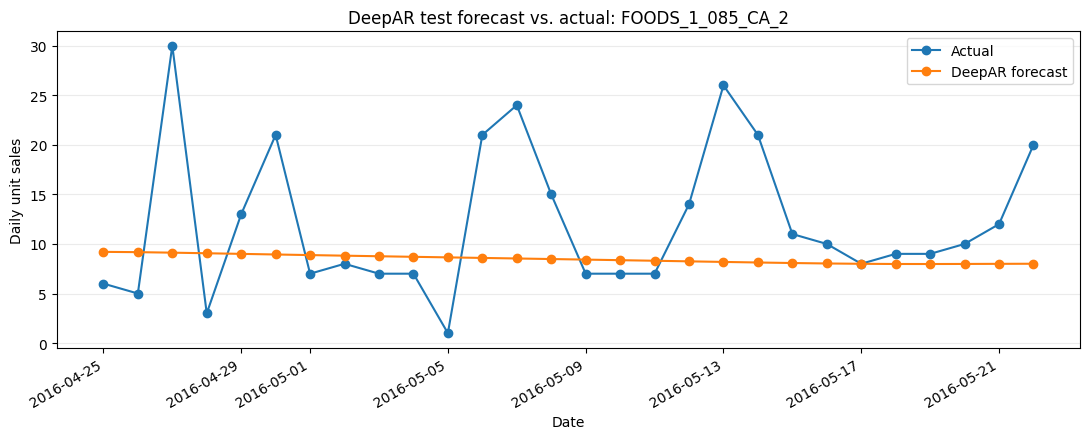

In [9]:
test_output = outputs["test"]
example_id = (
    test_output.groupby("unique_id", observed=True)["actual"]
    .sum()
    .idxmax()
)
plot_df = test_output.loc[test_output["unique_id"] == example_id].sort_values("ds")

fig, ax = plt.subplots(figsize=(11, 4.5))
ax.plot(plot_df["ds"], plot_df["actual"], marker="o", label="Actual")
ax.plot(plot_df["ds"], plot_df["forecast"], marker="o", label="DeepAR forecast")
ax.set(
    title=f"DeepAR test forecast vs. actual: {example_id}",
    xlabel="Date",
    ylabel="Daily unit sales",
)
ax.legend()
ax.grid(axis="y", alpha=0.25)
fig.autofmt_xdate()
fig.tight_layout()
plt.show()

## 8 - Outputs and next step

This notebook writes one row-level Parquet file per evaluation window plus `deepar_metrics.csv`. Each forecast file contains:

| Column | Meaning |
|---|---|
| `unique_id` | Product-store series |
| `ds` | Forecast date |
| `actual` | Observed unit sales |
| `forecast` | DeepAR point forecast |
| `abs_error` | Absolute forecast error |
| `model` | Model label (`DeepAR`) |
| `window` | `val_1`, `val_2`, or `test` |

The evaluation notebook can now join these forecasts to category, sales-speed, and price metadata to compare models and translate forecast error into safety-stock dollars.